<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/final_chocolate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import RidgeCV

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA

from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

In [91]:
url = "https://raw.githubusercontent.com/leeale2023/BA305_A9-/main/chocolate.csv"

choc = pd.read_csv(url)

print("Dataset shape:", choc.shape)
choc.head()

Dataset shape: (2530, 10)


,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


In [92]:
choc["cocoa_numeric"] = (
    choc["cocoa_percent"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

choc[["cocoa_percent", "cocoa_numeric"]].head()

,cocoa_percent,cocoa_numeric
0,76%,76.0
1,76%,76.0
2,76%,76.0
3,68%,68.0
4,72%,72.0


In [93]:
columns_used = [
    "company_location",
    "country_of_bean_origin",
    "ingredients",
    "cocoa_numeric",
    "most_memorable_characteristics",
    "rating"
]

missing_summary = pd.DataFrame({
    "Missing": choc[columns_used].isna().sum(),
    "Percent Missing": choc[columns_used].isna().mean() * 100
})

display(missing_summary)

,Missing,Percent Missing
company_location,0,0.000000
country_of_bean_origin,0,0.000000
ingredients,87,3.438735
cocoa_numeric,0,0.000000
most_memorable_characteristics,0,0.000000
rating,0,0.000000


In [94]:
choc_train, choc_test = train_test_split(
    choc,
    test_size=0.3,
    random_state=0
)

print("Training observations:", len(choc_train))
print("Testing observations:", len(choc_test))

Training observations: 1771
Testing observations: 759


In [95]:
C_train = choc_train["most_memorable_characteristics"].fillna("")
y_train_text = choc_train["rating"].values

vec = CountVectorizer(
    binary=True,
    stop_words=["and", "notes", "note", "of", "with", "a", "the"]
)

W_train = vec.fit_transform(C_train)

ridge = RidgeCV(
    alphas=np.logspace(-2, 3, 30)
)

ridge.fit(W_train, y_train_text)

word_scores = pd.Series(
    ridge.coef_,
    index=vec.get_feature_names_out()
)

print("Number of learned words:", len(word_scores))

display(
    word_scores.sort_values(ascending=False).head(10)
)

Number of learned words: 462


,0
raspberry,0.227333
grape,0.225805
blackberry,0.218016
complex,0.217586
balanced,0.215016
distinct,0.211914
fig,0.209135
dark,0.209103
cinnamon,0.208858
creamy,0.200559


In [96]:
analyzer = vec.build_analyzer()

def score_phrase(phrase):
    phrase = str(phrase).strip().lower()

    if phrase in word_scores.index:
        return word_scores[phrase]

    words = [
        word_scores[word]
        for word in analyzer(phrase)
        if word in word_scores.index
    ]

    if len(words) > 0:
        return np.mean(words)

    return 0.0


def calculate_sentiment_total(series):
    scores = []

    for item in series:
        total = 0.0

        for characteristic in str(item).split(","):
            characteristic = characteristic.strip().lower()

            if characteristic:
                total += score_phrase(characteristic)

        scores.append(total)

    return np.array(scores)

In [97]:
sentiment_train = calculate_sentiment_total(
    choc_train["most_memorable_characteristics"]
)

sentiment_test = calculate_sentiment_total(
    choc_test["most_memorable_characteristics"]
)

print("First five training sentiment scores:")
print(sentiment_train[:5])

First five training sentiment scores:
[ 0.02571819 -0.55211538  0.00517061 -0.5462892   0.42169369]


In [98]:
origin_dummies = pd.get_dummies(
    choc["country_of_bean_origin"],
    prefix="origin"
)

location_dummies = pd.get_dummies(
    choc["company_location"],
    prefix="location"
)

ingredients_dummies = pd.get_dummies(
    choc["ingredients"],
    prefix="ingredients"
)

X_all = pd.concat([
    origin_dummies,
    location_dummies,
    ingredients_dummies,
    choc[["cocoa_numeric"]]
], axis=1)

print("Number of predictors before sentiment:", X_all.shape[1])

Number of predictors before sentiment: 151


In [99]:
X_train = X_all.loc[choc_train.index].copy()
X_test = X_all.loc[choc_test.index].copy()

X_train["sentiment_total"] = sentiment_train
X_test["sentiment_total"] = sentiment_test

y_train = choc_train["rating"].values
y_test = choc_test["rating"].values

print("X train shape:", X_train.shape)
print("X test shape:", X_test.shape)

X train shape: (1771, 152)
X test shape: (759, 152)


In [100]:
pre_features = [
    col for col in X_train.columns
    if col != "sentiment_total"
]

X_train_pre = X_train[pre_features].copy()
X_test_pre = X_test[pre_features].copy()

print("Pre-tasting train shape:", X_train_pre.shape)
print("Pre-tasting test shape:", X_test_pre.shape)

Pre-tasting train shape: (1771, 151)
Pre-tasting test shape: (759, 151)


In [101]:
# Pre-tasting KNN

scaler_pre = StandardScaler()

X_train_pre_scaled = scaler_pre.fit_transform(X_train_pre)
X_test_pre_scaled = scaler_pre.transform(X_test_pre)

knn_pre = KNeighborsRegressor(
    n_neighbors=50,
    weights="uniform"
)

knn_pre.fit(
    X_train_pre_scaled,
    y_train
)

y_test_pred_knn_pre = knn_pre.predict(
    X_test_pre_scaled
)

knn_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_knn_pre)
)

knn_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_knn_pre
)

print(f"Pre-tasting KNN Test RMSE: {knn_pre_rmse:.3f}")
print(f"Pre-tasting KNN Test MAE:  {knn_pre_mae:.3f}")

Pre-tasting KNN Test RMSE: 0.417
Pre-tasting KNN Test MAE:  0.341


In [102]:
# Pre-tasting Decision Tree

dt_pre = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=5,
    random_state=0
)

dt_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_dt_pre = dt_pre.predict(
    X_test_pre
)

dt_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt_pre)
)

dt_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt_pre
)

print(f"Pre-tasting Decision Tree Test RMSE: {dt_pre_rmse:.3f}")
print(f"Pre-tasting Decision Tree Test MAE:  {dt_pre_mae:.3f}")# Pre-tasting Gradient Boosting

gb_pre = GradientBoostingRegressor(
    random_state=0
)

gb_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_gb_pre = gb_pre.predict(
    X_test_pre
)

gb_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_gb_pre)
)

gb_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_gb_pre
)

print(f"Pre-tasting Gradient Boosting Test RMSE: {gb_pre_rmse:.3f}")
print(f"Pre-tasting Gradient Boosting Test MAE:  {gb_pre_mae:.3f}")

Pre-tasting Decision Tree Test RMSE: 0.407
Pre-tasting Decision Tree Test MAE:  0.331
Pre-tasting Gradient Boosting Test RMSE: 0.403
Pre-tasting Gradient Boosting Test MAE:  0.329


In [103]:
# Tune pre-tasting KNN

neighbors_list = [1, 5, 10, 50, 100]
weights_list = ["uniform", "distance"]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_pre_results = []

for weight in weights_list:
    for k in neighbors_list:

        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        cv_scores = cross_val_score(
            model,
            X_train_pre_scaled,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        knn_pre_results.append([
            k,
            weight,
            cv_rmse
        ])

knn_pre_results = pd.DataFrame(
    knn_pre_results,
    columns=[
        "Neighbors",
        "Weight",
        "CV RMSE"
    ]
)

knn_pre_results = knn_pre_results.sort_values(
    "CV RMSE"
)

display(knn_pre_results)

,Neighbors,Weight,CV RMSE
3,50,uniform,0.451334
4,100,uniform,0.452587
2,10,uniform,0.457417
1,5,uniform,0.465463
9,100,distance,0.470606
8,50,distance,0.471581
7,10,distance,0.479582
6,5,distance,0.486641
5,1,distance,0.571724
0,1,uniform,0.571724


In [104]:
# Tune pre-tasting Decision Tree

depth_list = [2, 3, 4, 5, 6, 8, 10, 12]
leaf_list = [1, 2, 5, 10, 20, 30]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_pre_results = []

for depth in depth_list:
    for leaf in leaf_list:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=0
        )

        cv_scores = cross_val_score(
            model,
            X_train_pre,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        tree_pre_results.append([
            depth,
            leaf,
            cv_rmse
        ])

tree_pre_results = pd.DataFrame(
    tree_pre_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "CV RMSE"
    ]
)

tree_pre_results = tree_pre_results.sort_values(
    "CV RMSE"
)

display(tree_pre_results.head(15))

,Max Depth,Min Samples Leaf,CV RMSE
27,6,10,0.433115
21,5,10,0.434013
20,5,5,0.434962
15,4,10,0.434984
39,10,10,0.435174
14,4,5,0.435308
45,12,10,0.436176
33,8,10,0.436216
41,10,30,0.436281
47,12,30,0.436281


In [105]:
# Final pre-tasting Decision Tree using tuned settings

dt_pre = DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=10,
    random_state=0
)

dt_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_dt_pre = dt_pre.predict(
    X_test_pre
)

dt_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt_pre)
)

dt_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt_pre
)

print(f"Pre-tasting Decision Tree Test RMSE: {dt_pre_rmse:.3f}")
print(f"Pre-tasting Decision Tree Test MAE:  {dt_pre_mae:.3f}")

Pre-tasting Decision Tree Test RMSE: 0.404
Pre-tasting Decision Tree Test MAE:  0.330


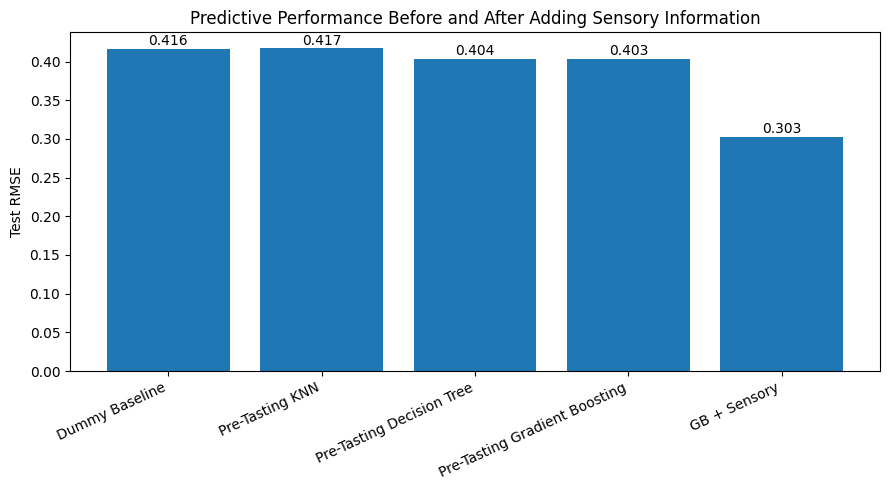

In [106]:
# Compare pre-tasting and sensory-enhanced model performance

model_names = [
    "Dummy Baseline",
    "Pre-Tasting KNN",
    "Pre-Tasting Decision Tree",
    "Pre-Tasting Gradient Boosting",
    "GB + Sensory"
]

rmse_values = [
    0.416,
    0.417,
    0.404,
    0.403,
    0.303
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    rmse_values
)

plt.ylabel("Test RMSE")
plt.title(
    "Predictive Performance Before and After Adding Sensory Information"
)

plt.xticks(
    rotation=25,
    ha="right"
)

for bar, value in zip(bars, rmse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [107]:
dummy = DummyRegressor(strategy="mean")

dummy.fit(X_train, y_train)

y_test_pred_dummy = dummy.predict(X_test)

dummy_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dummy)
)

dummy_mae = mean_absolute_error(
    y_test,
    y_test_pred_dummy
)

print(f"Baseline Test RMSE: {dummy_rmse:.3f}")
print(f"Baseline Test MAE:  {dummy_mae:.3f}")

Baseline Test RMSE: 0.416
Baseline Test MAE:  0.342


In [108]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [109]:
neighbors_list = [1, 5, 10, 50, 100]
weights_list = ["uniform", "distance"]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_results = []

for weight in weights_list:

    for k in neighbors_list:

        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        cv_scores = cross_val_score(
            model,
            X_train_scaled,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        knn_results.append([
            k,
            weight,
            cv_rmse
        ])

knn_results = pd.DataFrame(
    knn_results,
    columns=[
        "Neighbors",
        "Weight",
        "CV RMSE"
    ]
)

knn_results = knn_results.sort_values(
    "CV RMSE"
)

display(knn_results)

,Neighbors,Weight,CV RMSE
8,50,distance,0.399990
9,100,distance,0.400274
7,10,distance,0.403881
4,100,uniform,0.407981
2,10,uniform,0.408294
3,50,uniform,0.409042
1,5,uniform,0.410938
6,5,distance,0.412696
5,1,distance,0.495448
0,1,uniform,0.495448


In [110]:
best_k = 50
best_weight = "uniform"

print("Selected number of neighbors:", best_k)
print("Selected weighting:", best_weight)

Selected number of neighbors: 50
Selected weighting: uniform


In [111]:
best_knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights=best_weight
)

best_knn.fit(
    X_train_scaled,
    y_train
)

y_train_pred_knn = best_knn.predict(
    X_train_scaled
)

y_test_pred_knn = best_knn.predict(
    X_test_scaled
)

knn_train_rmse = np.sqrt(
    MSE(y_train, y_train_pred_knn)
)

knn_rmse = np.sqrt(
    MSE(y_test, y_test_pred_knn)
)

knn_mae = mean_absolute_error(
    y_test,
    y_test_pred_knn
)

print(f"KNN Train RMSE: {knn_train_rmse:.3f}")
print(f"KNN Test RMSE:  {knn_rmse:.3f}")
print(f"KNN Test MAE:   {knn_mae:.3f}")

KNN Train RMSE: 0.401
KNN Test RMSE:  0.381
KNN Test MAE:   0.309


In [112]:
depth_list = [2, 3, 4, 5, 6, 8, 10, 12]

leaf_list = [
    1, 2, 5, 10, 20, 30
]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_results = []

for depth in depth_list:

    for leaf in leaf_list:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=0
        )

        cv_scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(
            -cv_scores.mean()
        )

        tree_results.append([
            depth,
            leaf,
            cv_rmse
        ])

tree_results = pd.DataFrame(
    tree_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "CV RMSE"
    ]
)

tree_results = tree_results.sort_values(
    "CV RMSE"
)

display(tree_results.head(15))

,Max Depth,Min Samples Leaf,CV RMSE
14,4,5,0.308794
13,4,2,0.309451
12,4,1,0.310006
6,3,1,0.310556
20,5,5,0.310773
8,3,5,0.310788
7,3,2,0.310788
11,3,30,0.311010
17,4,30,0.312247
18,5,1,0.312974


In [113]:
best_depth = int(
    tree_results.iloc[0]["Max Depth"]
)

best_leaf = int(
    tree_results.iloc[0]["Min Samples Leaf"]
)

print("Best max depth:", best_depth)
print("Best min samples leaf:", best_leaf)
print(
    "Best CV RMSE:",
    round(tree_results.iloc[0]["CV RMSE"], 3)
)

Best max depth: 4
Best min samples leaf: 5
Best CV RMSE: 0.309


In [114]:
best_dt = DecisionTreeRegressor(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=0
)

best_dt.fit(
    X_train,
    y_train
)

y_train_pred_dt = best_dt.predict(
    X_train
)

y_test_pred_dt = best_dt.predict(
    X_test
)

dt_train_rmse = np.sqrt(
    MSE(y_train, y_train_pred_dt)
)

dt_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt)
)

dt_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt
)

print(f"Decision Tree Train RMSE: {dt_train_rmse:.3f}")
print(f"Decision Tree Test RMSE:  {dt_rmse:.3f}")
print(f"Decision Tree Test MAE:   {dt_mae:.3f}")

Decision Tree Train RMSE: 0.292
Decision Tree Test RMSE:  0.308
Decision Tree Test MAE:   0.242


In [115]:
best_boost = GradientBoostingRegressor(random_state=0)

best_boost.fit(X_train, y_train)

y_train_pred_boost = best_boost.predict(X_train)
y_test_pred_boost = best_boost.predict(X_test)

boost_train_rmse = np.sqrt(MSE(y_train, y_train_pred_boost))
boost_rmse = np.sqrt(MSE(y_test, y_test_pred_boost))
boost_mae = mean_absolute_error(y_test, y_test_pred_boost)

print(f"Gradient Boosting Train RMSE: {boost_train_rmse:.3f}")
print(f"Gradient Boosting Test RMSE: {boost_rmse:.3f}")
print(f"Gradient Boosting Test MAE: {boost_mae:.3f}")

Gradient Boosting Train RMSE: 0.264
Gradient Boosting Test RMSE: 0.303
Gradient Boosting Test MAE: 0.238


In [116]:
model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "Gradient Boosting"
    ],

    "Test RMSE": [
        dummy_rmse,
        knn_rmse,
        dt_rmse,
        boost_rmse
    ],

    "Test MAE": [
        dummy_mae,
        knn_mae,
        dt_mae,
        boost_mae
    ]
})

model_comparison = model_comparison.sort_values(
    "Test RMSE"
)

display(model_comparison)

,Model,Test RMSE,Test MAE
3,Gradient Boosting,0.303358,0.237826
2,Decision Tree,0.307912,0.241821
1,KNN,0.381134,0.308709
0,Dummy Baseline,0.416081,0.341947


In [117]:
boost_feature_importance = pd.Series(
    best_boost.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

display(
    boost_feature_importance.head(20)
)

,0
sentiment_total,0.856774
cocoa_numeric,0.046560
location_Belgium,0.015178
origin_Blend,0.012931
"ingredients_3- B,S,C",0.010309
"ingredients_2- B,S",0.004698
location_U.K.,0.004402
"ingredients_4- B,S,C,L",0.003944
location_Canada,0.002968
"ingredients_3- B,S,L",0.002826


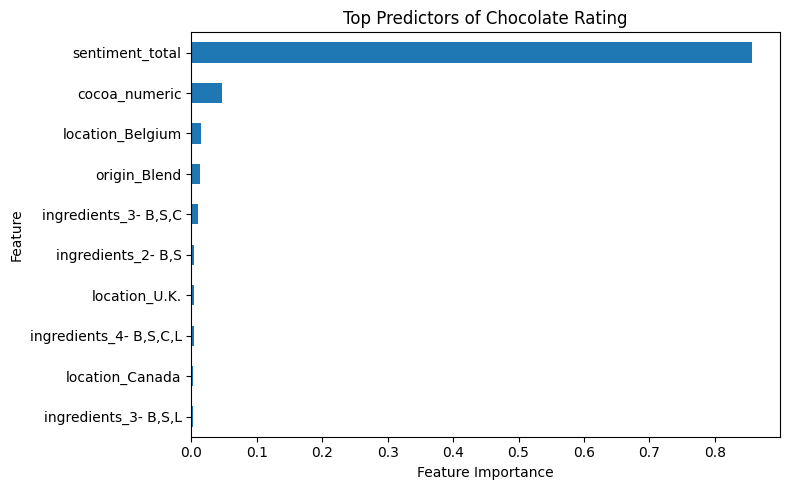

In [118]:
top_features = (
    boost_feature_importance
    .head(10)
    .sort_values()
)

plt.figure(figsize=(8, 5))

top_features.plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top Predictors of Chocolate Rating"
)

plt.tight_layout()
plt.show()

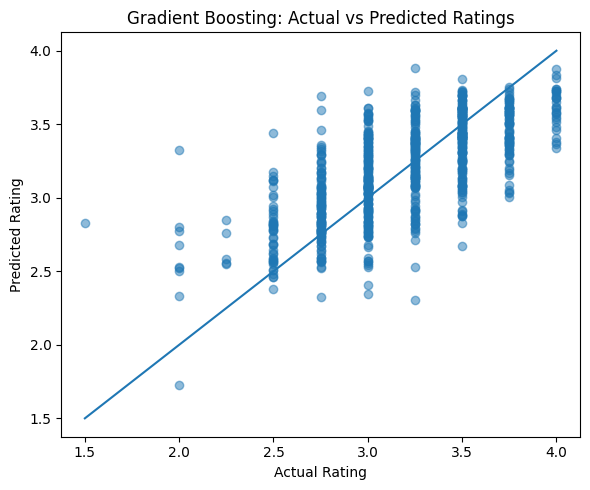

In [119]:
plt.figure(figsize=(6, 5))

plt.scatter(
    y_test,
    y_test_pred_boost,
    alpha=0.5
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.title(
    "Gradient Boosting: Actual vs Predicted Ratings"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.tight_layout()
plt.show()

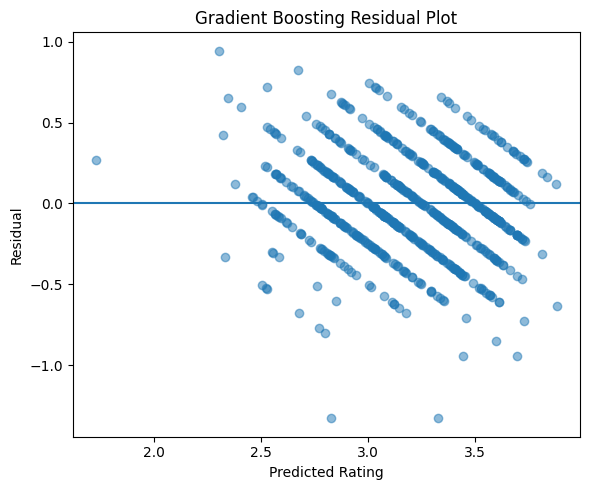

In [120]:
residuals = (
    y_test - y_test_pred_boost
)

plt.figure(figsize=(6, 5))

plt.scatter(
    y_test_pred_boost,
    residuals,
    alpha=0.5
)

plt.axhline(0)

plt.xlabel("Predicted Rating")
plt.ylabel("Residual")

plt.title(
    "Gradient Boosting Residual Plot"
)

plt.tight_layout()
plt.show()

In [121]:
error_details = choc_test[
    [
        "company_location",
        "country_of_bean_origin",
        "cocoa_percent",
        "ingredients",
        "most_memorable_characteristics",
        "rating"
    ]
].copy()

error_details["Predicted"] = (
    y_test_pred_boost
)

error_details["Absolute Error"] = abs(
    error_details["rating"]
    - error_details["Predicted"]
)

error_details = (
    error_details
    .sort_values(
        "Absolute Error",
        ascending=False
    )
)

display(
    error_details.head(20)
)

,company_location,country_of_bean_origin,cocoa_percent,ingredients,most_memorable_characteristics,rating,Predicted,Absolute Error
2118,U.S.A.,Ghana,67%,"3- B,S,C","perfume, strong chemical",1.50,2.828566,1.328566
883,Switzerland,Blend,62%,"5- B,S,C,V,L","malitol, cocoa",2.00,3.327894,1.327894
1687,U.S.A.,Peru,75%,"3- B,S,C","spicy, red fruit, raisins",2.75,3.694743,0.944743
2293,U.S.A.,Blend,99%,NaN,"spicy, ginger, bitter",3.25,2.305289,0.944711
1027,U.S.A.,Peru,70%,"3- B,S,C","oily, tart, chlorine",2.50,3.442314,0.942314
670,U.S.A.,Liberia,70%,"2- B,S","roasty, spicy, nutty",2.75,3.598432,0.848432
1427,Madagascar,Madagascar,75%,"5- B,S,C,V,L","sticky, bitter, nutty",3.50,2.673276,0.826724
1446,Italy,Ecuador,70%,"4- B,S,C,L","strong vanilla, some spice",2.00,2.800428,0.800428
1165,Ecuador,Ecuador,80%,"4- B,S,C,L","perfume, burning",2.00,2.772421,0.772421
1428,Madagascar,Madagascar,70%,"5- B,S,C,V,L","sandy, woody, peanut butter",3.75,3.004072,0.745928


In [122]:
feature_sets = {
    "All Predictors":
        list(X_train.columns),

    "Without Company Location":
        [
            col for col in X_train.columns
            if not col.startswith("location_")
        ],

    "Without Bean Origin":
        [
            col for col in X_train.columns
            if not col.startswith("origin_")
        ],

    "Without Sentiment":
        [
            col for col in X_train.columns
            if col != "sentiment_total"
        ],

    "Cocoa + Ingredients + Sentiment":
        [
            col for col in X_train.columns
            if (
                col == "cocoa_numeric"
                or col == "sentiment_total"
                or col.startswith("ingredients_")
            )
        ]
}

ablation_results = []

for name, features in feature_sets.items():

    model = GradientBoostingRegressor(
        random_state=0
    )

    model.fit(
        X_train[features],
        y_train
    )

    predictions = model.predict(
        X_test[features]
    )

    rmse = np.sqrt(
        MSE(y_test, predictions)
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    ablation_results.append([
        name,
        len(features),
        rmse,
        mae
    ])

ablation_results = pd.DataFrame(
    ablation_results,
    columns=[
        "Feature Set",
        "Number of Predictors",
        "Test RMSE",
        "Test MAE"
    ]
)

ablation_results = ablation_results.sort_values(
    "Test RMSE"
)

display(ablation_results)

,Feature Set,Number of Predictors,Test RMSE,Test MAE
0,All Predictors,152,0.303358,0.237826
2,Without Bean Origin,90,0.303418,0.238451
4,Cocoa + Ingredients + Sentiment,23,0.304692,0.240132
1,Without Company Location,85,0.305608,0.239285
3,Without Sentiment,151,0.402610,0.329124


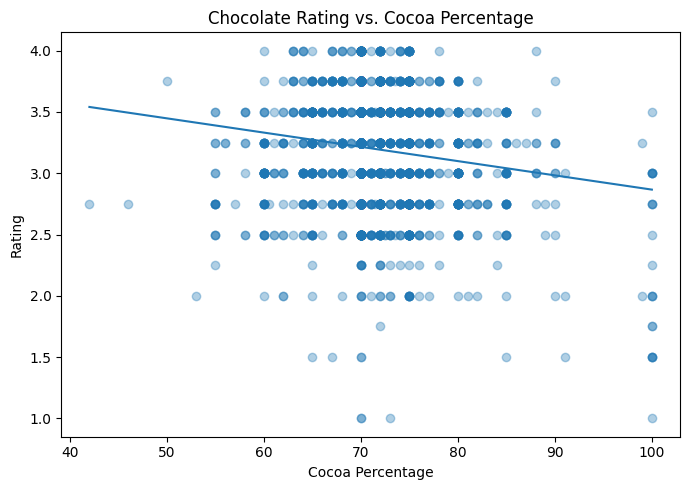

Correlation between cocoa percentage and rating: -0.147


In [123]:
plt.figure(figsize=(7, 5))

plt.scatter(
    choc["cocoa_numeric"],
    choc["rating"],
    alpha=0.35
)

z = np.polyfit(
    choc["cocoa_numeric"],
    choc["rating"],
    1
)

p = np.poly1d(z)

x_line = np.linspace(
    choc["cocoa_numeric"].min(),
    choc["cocoa_numeric"].max(),
    100
)

plt.plot(
    x_line,
    p(x_line),
)

plt.xlabel("Cocoa Percentage")
plt.ylabel("Rating")
plt.title("Chocolate Rating vs. Cocoa Percentage")

plt.tight_layout()
plt.show()

cocoa_rating_corr = choc[
    ["cocoa_numeric", "rating"]
].corr().iloc[0, 1]

print(
    "Correlation between cocoa percentage and rating:",
    round(cocoa_rating_corr, 3)
)

,count,mean,median,std
country_of_bean_origin,,,,
Madagascar,177,3.266949,3.25,0.387659
Nicaragua,100,3.255000,3.25,0.381021
Tanzania,79,3.234177,3.25,0.384686
Venezuela,253,3.231225,3.25,0.464934
Dominican Republic,226,3.215708,3.25,0.385410
Peru,244,3.197746,3.25,0.485473
Colombia,79,3.196203,3.25,0.423036
Bolivia,80,3.181250,3.25,0.435699
Ecuador,219,3.164384,3.25,0.512268


<Figure size 1000x600 with 0 Axes>

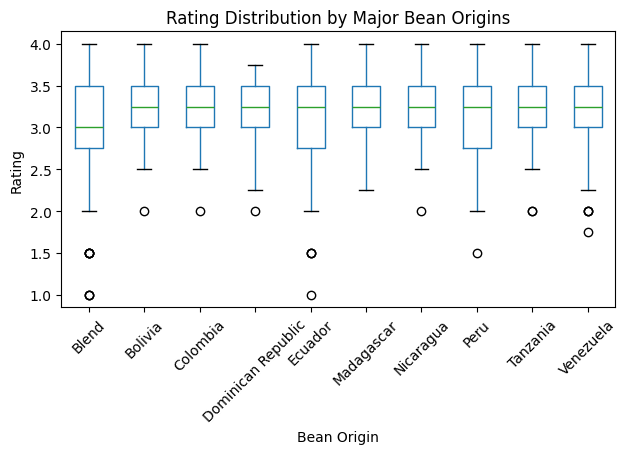

In [124]:
top_origins = (
    choc["country_of_bean_origin"]
    .value_counts()
    .head(10)
    .index
)

origin_data = choc[
    choc["country_of_bean_origin"].isin(top_origins)
].copy()

origin_summary = (
    origin_data
    .groupby("country_of_bean_origin")["rating"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)

display(origin_summary)

plt.figure(figsize=(10, 6))

origin_data.boxplot(
    column="rating",
    by="country_of_bean_origin",
    grid=False,
    rot=45
)

plt.xlabel("Bean Origin")
plt.ylabel("Rating")
plt.title("Rating Distribution by Major Bean Origins")
plt.suptitle("")

plt.tight_layout()
plt.show()

In [125]:
feature_counts = (
    sensory_dummies
    .sum()
    .sort_values(
        ascending=False
    )
)

q90 = feature_counts.quantile(0.90)

common_features = (
    feature_counts[
        feature_counts >= q90
    ]
    .index
)

pca_features = sensory_dummies[
    common_features
]

print(
    "Number of sensory features used:",
    pca_features.shape[1]
)

Number of sensory features used: 101


In [126]:
pca = PCA(
    n_components=2
)

pca_result = pca.fit_transform(
    pca_features
)

pca_df = pd.DataFrame(
    pca_result,
    columns=[
        "PC1",
        "PC2"
    ],
    index=choc.index
)

print(
    "PC1 explained variance:",
    round(
        pca.explained_variance_ratio_[0],
        4
    )
)

print(
    "PC2 explained variance:",
    round(
        pca.explained_variance_ratio_[1],
        4
    )
)

print(
    "Total explained variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

PC1 explained variance: 0.0551
PC2 explained variance: 0.0479
Total explained variance: 0.103


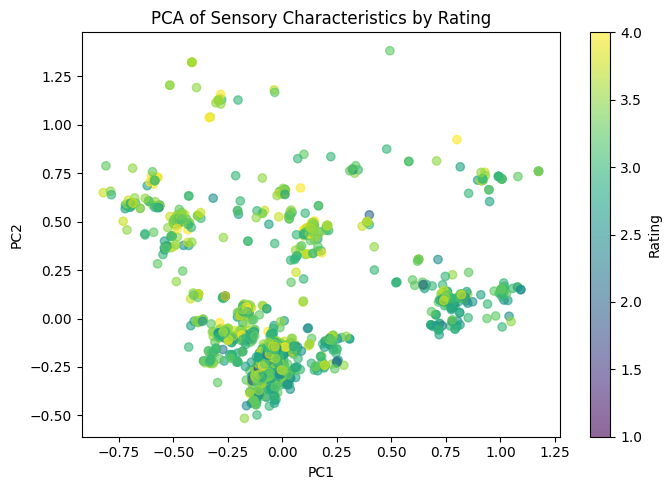

In [127]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=choc["rating"],
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Rating"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA of Sensory Characteristics by Rating"
)

plt.tight_layout()
plt.show()

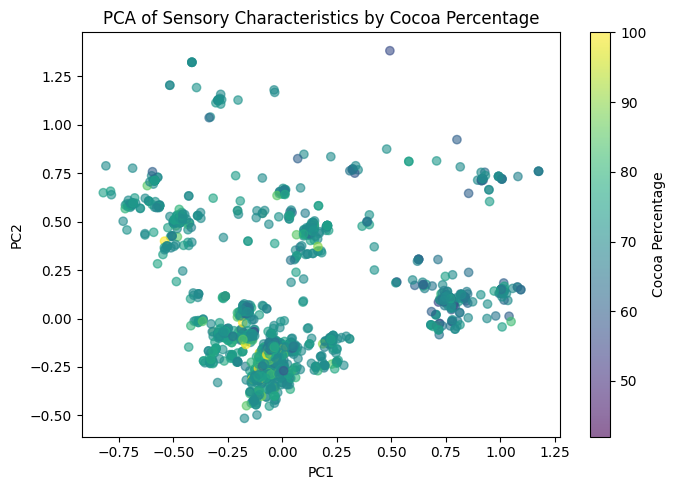

In [128]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=choc["cocoa_numeric"],
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Cocoa Percentage"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA of Sensory Characteristics by Cocoa Percentage"
)

plt.tight_layout()
plt.show()